In [3]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import torch
from sklearn.preprocessing import MinMaxScaler

# Project paths
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent.parent
elif PROJECT_ROOT.name == "models":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "models" /"data" / "processed" / "fifa_workload_1min.csv"
MODEL_PATH = PROJECT_ROOT / "models" / "cnn_transformer.pth"

# Import the model definition
sys.path.insert(0, str(PROJECT_ROOT / "models"))
from cnn_transformer import CNNTransformer

# Device
device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)

# Load workload
workload = pd.read_csv(DATA_PATH)
values = workload["requests"].to_numpy(dtype=np.float32)

# Recreate the chronological split used for training
split_idx = int(len(values) * 0.7)
train_raw = values[:split_idx]
test_raw = values[split_idx:]

# Refit scaler on training data only
scaler = MinMaxScaler()
scaler.fit(train_raw.reshape(-1, 1))

# Load saved model
checkpoint = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=True
)

model = CNNTransformer(
    input_features=1,
    cnn_channels=16,
    kernel_size=3,
    d_model=64,
    nhead=4,
    num_encoder_layers=1,
    dim_feedforward=128,
    dropout=0.1,
    prediction_horizon=1,
).to(device)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Setup successful")
print("Device:", device)
print("Total minutes:", len(values))
print("Training minutes:", len(train_raw))
print("Test minutes:", len(test_raw))

Setup successful
Device: mps
Total minutes: 10080
Training minutes: 8064
Test minutes: 2016


In [4]:
SEQ_LEN = checkpoint["sequence_length"]

X_test = []

for i in range(len(test_raw)):
    # History ends immediately before the minute being predicted
    history_end = split_idx + i
    history = values[history_end - SEQ_LEN:history_end]

    scaled_history = scaler.transform(
        history.reshape(-1, 1)
    ).astype(np.float32)

    X_test.append(scaled_history)

X_test = np.stack(X_test)

forecasts_scaled = []

with torch.no_grad():
    for start in range(0, len(X_test), 32):
        batch = torch.from_numpy(
            X_test[start:start + 32]
        ).to(device)

        output = model(batch)
        forecasts_scaled.extend(
            output.cpu().numpy().reshape(-1)
        )

forecasts = scaler.inverse_transform(
    np.asarray(forecasts_scaled).reshape(-1, 1)
).flatten()

forecasts = np.maximum(forecasts, 0)

assert len(forecasts) == len(test_raw)

print("Forecasts generated:", len(forecasts))
print("First five forecasts:", forecasts[:5])

Forecasts generated: 2016
First five forecasts: [585.6165  603.0286  615.8906  665.9919  671.03284]


In [5]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import torch
from sklearn.preprocessing import MinMaxScaler

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent.parent
elif PROJECT_ROOT.name == "models":
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT / "models"))

from cnn_transformer import CNNTransformer

device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)

checkpoint_path = PROJECT_ROOT / "models" / "cnn_transformer.pth"
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model = CNNTransformer(
    input_features=1,
    cnn_channels=16,
    kernel_size=3,
    d_model=64,
    nhead=4,
    num_encoder_layers=1,
    dim_feedforward=128,
    dropout=0.1,
    prediction_horizon=1,
).to(device)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Model loaded on:", device)

Model loaded on: mps


In [6]:
import numpy as np
import pandas as pd

REPLICA_CAPACITY = 100
MIN_REPLICAS = 1
MAX_REPLICAS = 20


def required_replicas(demand):
    return int(np.clip(
        np.ceil(max(0, demand) / REPLICA_CAPACITY),
        MIN_REPLICAS,
        MAX_REPLICAS
    ))



def run_scaler(
    actual_demand,
    predicted_demand=None,
    cooldown_minutes=0,
):
    replicas = MIN_REPLICAS
    last_scale_time = -10**9
    history = []

    for t, actual in enumerate(actual_demand):

        if predicted_demand is None:
            # Reactive: use only previously observed demand.
            if t == 0:
                signal = None
                desired = replicas
            else:
                signal = actual_demand[t - 1]
                desired = required_replicas(signal)
        else:
            # Predictive: forecast for the current minute,
            # generated using earlier workload history.
            signal = predicted_demand[t]
            desired = required_replicas(signal)

        can_scale = (
            t - last_scale_time >= cooldown_minutes
        )

        if desired != replicas and can_scale:
            replicas = desired
            last_scale_time = t

        capacity = replicas * REPLICA_CAPACITY
        overload = max(0, actual - capacity)

        history.append({
            "minute": t,
            "actual_demand": float(actual),
            "scaling_signal": (
                float(signal) if signal is not None else None
            ),
            "replicas": replicas,
            "capacity": capacity,
            "overload_requests": overload,
            "under_capacity": actual > capacity,
        })

    return pd.DataFrame(history)


print("Simulator ready")

Simulator ready


In [7]:
def run_adaptive_scaler(
    actual_demand,
    predicted_demand,
    base_cooldown=3,
    min_cooldown=1,
    max_cooldown=10,
    error_window=10,
    error_threshold=100,
):
    replicas = MIN_REPLICAS
    last_scale_time = -10**9
    history = []
    recent_errors = []

    for t, actual in enumerate(actual_demand):
        forecast = max(0, float(predicted_demand[t]))

        # Use only errors from forecasts whose actual demand is now observed.
        if t > 0:
            previous_error = abs(
                float(actual_demand[t - 1])
                - float(predicted_demand[t - 1])
            )
            recent_errors.append(previous_error)

        recent_errors = recent_errors[-error_window:]

        if recent_errors:
            mean_error = float(np.mean(recent_errors))
        else:
            mean_error = 0.0

        # High recent error -> longer cooldown.
        # Low recent error -> shorter cooldown.
        if mean_error > error_threshold:
            cooldown = min(max_cooldown, base_cooldown * 2)
        else:
            cooldown = max(min_cooldown, base_cooldown // 2)

        desired = required_replicas(forecast)
        can_scale = (t - last_scale_time) >= cooldown

        if desired != replicas and can_scale:
            replicas = desired
            last_scale_time = t

        capacity = replicas * REPLICA_CAPACITY
        overload = max(0, float(actual) - capacity)

        history.append({
            "minute": t,
            "actual_demand": float(actual),
            "forecast": forecast,
            "mean_recent_error": mean_error,
            "cooldown_minutes": cooldown,
            "replicas": replicas,
            "capacity": capacity,
            "overload_requests": overload,
            "under_capacity": actual > capacity,
        })

    return pd.DataFrame(history)

In [8]:

def run_uncertainty_aware_scaler(
    actual_demand,
    predicted_demand,
    error_window=10,
    safety_factor=1.0,
):
    actual_demand = np.asarray(actual_demand, dtype=float)
    predicted_demand = np.asarray(predicted_demand, dtype=float)

    if len(actual_demand) != len(predicted_demand):
        raise ValueError("Actual and predicted demand lengths differ.")

    if len(actual_demand) == 0:
        raise ValueError("Demand arrays cannot be empty.")

    if error_window < 1 or safety_factor < 0:
        raise ValueError("Invalid error_window or safety_factor.")

    replicas = MIN_REPLICAS
    history = []
    past_errors = []

    for t in range(len(actual_demand)):
        forecast = max(0.0, float(predicted_demand[t]))

        # Only use errors from previous, completed forecasts.
        recent_errors = past_errors[-error_window:]

        uncertainty = (
            float(np.mean(recent_errors))
            if recent_errors else 0.0
        )

        safe_demand = forecast + safety_factor * uncertainty

        desired = required_replicas(safe_demand)
        replicas = desired

        capacity = replicas * REPLICA_CAPACITY
        actual = float(actual_demand[t])
        overload = max(0.0, actual - capacity)

        history.append({
            "minute": t,
            "actual_demand": actual,
            "forecast": forecast,
            "uncertainty": uncertainty,
            "safe_demand": safe_demand,
            "safety_factor": safety_factor,
            "replicas": replicas,
            "capacity": capacity,
            "overload_requests": overload,
            "under_capacity": actual > capacity,
        })

        # The current error is available only after this decision.
        past_errors.append(abs(actual - forecast))

    return pd.DataFrame(history)


In [9]:
# Generate one-minute-ahead forecasts using the loaded model

SEQ_LEN = checkpoint["sequence_length"]

X_test = []

for i in range(len(test_raw)):
    history_end = split_idx + i
    history = values[history_end - SEQ_LEN:history_end]

    scaled_history = scaler.transform(
        history.reshape(-1, 1)
    ).astype(np.float32)

    X_test.append(scaled_history)

X_test = np.stack(X_test)

forecasts_scaled = []

model.eval()

with torch.no_grad():
    for start in range(0, len(X_test), 32):
        batch = torch.from_numpy(
            X_test[start:start + 32]
        ).to(device)

        output = model(batch)

        forecasts_scaled.extend(
            output.cpu().numpy().reshape(-1)
        )

forecasts = scaler.inverse_transform(
    np.asarray(forecasts_scaled).reshape(-1, 1)
).flatten()

forecasts = np.maximum(forecasts, 0)

print("Actual test values:", len(test_raw))
print("Forecasts generated:", len(forecasts))

assert len(test_raw) == len(forecasts)
print("Forecast generation successful!")

Actual test values: 2016
Forecasts generated: 2016
Forecast generation successful!


In [10]:
reactive_results = run_scaler(
    test_raw,
    predicted_demand=None,
    cooldown_minutes=0,
)

predictive_results = run_scaler(
    test_raw,
    predicted_demand=forecasts,
    cooldown_minutes=0,
)

print("Reactive controller")
display(reactive_results.head())

print("Predictive controller")
display(predictive_results.head())

Reactive controller


,minute,actual_demand,scaling_signal,replicas,capacity,overload_requests,under_capacity
0,0,593.0,NaN,1,100,493.0,True
1,1,609.0,593.0,6,600,9.0,True
2,2,694.0,609.0,7,700,0.0,False
3,3,670.0,694.0,7,700,0.0,False
4,4,622.0,670.0,7,700,0.0,False


Predictive controller


,minute,actual_demand,scaling_signal,replicas,capacity,overload_requests,under_capacity
0,0,593.0,585.616516,6,600,0.0,False
1,1,609.0,603.028625,7,700,0.0,False
2,2,694.0,615.890625,7,700,0.0,False
3,3,670.0,665.991882,7,700,0.0,False
4,4,622.0,671.032837,7,700,0.0,False


In [11]:
def summarize_controller(name, results):
    changes = results["replicas"].diff().fillna(0)

    return {
        "Controller": name,
        "Mean replicas": results["replicas"].mean(),
        "Peak replicas": results["replicas"].max(),
        "Total overload requests": results["overload_requests"].sum(),
        "Minutes overloaded": results["under_capacity"].sum(),
        "Scaling changes": changes.ne(0).sum(),
    }


comparison = pd.DataFrame([
    summarize_controller("Reactive", reactive_results),
    summarize_controller("Predictive", predictive_results),
])

display(comparison.round(2))

,Controller,Mean replicas,Peak replicas,Total overload requests,Minutes overloaded,Scaling changes
0,Reactive,10.93,20,90328.0,737,1392
1,Predictive,11.10,20,68937.0,589,1058


Mean absolute prediction error: 112.16
Median absolute prediction error: 84.65
90th percentile error: 242.94


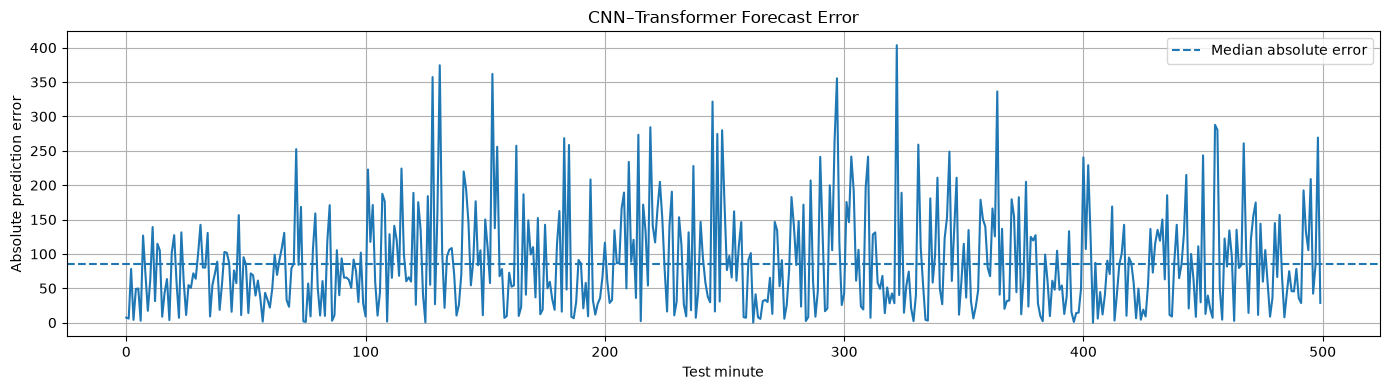

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Forecast error for each test minute
prediction_errors = np.abs(test_raw - forecasts)

print("Mean absolute prediction error:",
      round(prediction_errors.mean(), 2))
print("Median absolute prediction error:",
      round(np.median(prediction_errors), 2))
print("90th percentile error:",
      round(np.percentile(prediction_errors, 90), 2))

plt.figure(figsize=(14, 4))
plt.plot(prediction_errors[:500])
plt.axhline(
    np.median(prediction_errors),
    linestyle="--",
    label="Median absolute error"
)
plt.xlabel("Test minute")
plt.ylabel("Absolute prediction error")
plt.title("CNN–Transformer Forecast Error")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [13]:
adaptive_results = run_adaptive_scaler(
    test_raw,
    forecasts,
)

comparison = pd.DataFrame([
    summarize_controller("Reactive", reactive_results),
    summarize_controller("Predictive", predictive_results),
    summarize_controller("Adaptive cooldown", adaptive_results),
])

display(comparison.round(2))

,Controller,Mean replicas,Peak replicas,Total overload requests,Minutes overloaded,Scaling changes
0,Reactive,10.93,20,90328.0,737,1392
1,Predictive,11.10,20,68937.0,589,1058
2,Adaptive cooldown,11.12,20,79518.0,623,520


Cooldown distribution:


,Number of minutes
Cooldown (minutes),
1,890
6,1126


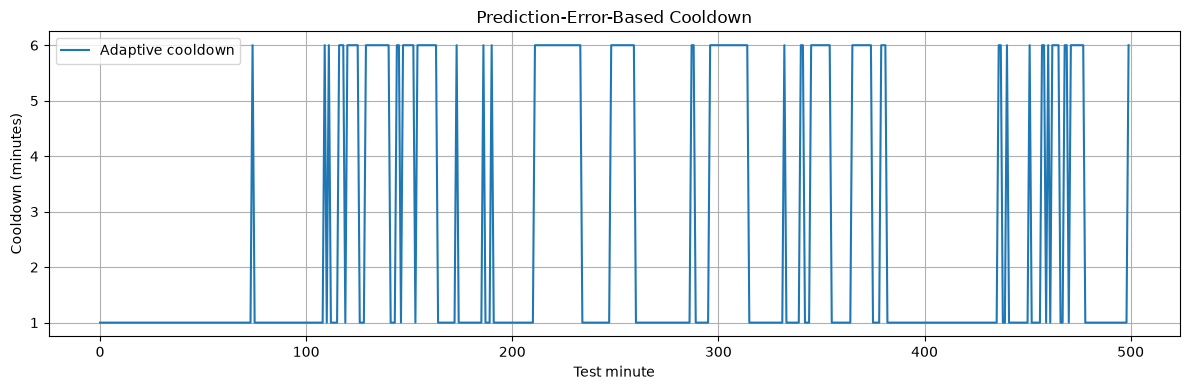

In [14]:
print("Cooldown distribution:")
display(
    adaptive_results["cooldown_minutes"]
    .value_counts()
    .sort_index()
    .rename_axis("Cooldown (minutes)")
    .to_frame("Number of minutes")
)

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.plot(
    adaptive_results["cooldown_minutes"][:500],
    label="Adaptive cooldown",
)
plt.xlabel("Test minute")
plt.ylabel("Cooldown (minutes)")
plt.title("Prediction-Error-Based Cooldown")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [15]:
comparison = pd.DataFrame([
    summarize_controller("Reactive", reactive_results),
    summarize_controller("Predictive", predictive_results),
    summarize_controller("Adaptive cooldown", adaptive_results),
])

display(comparison.round(2))

,Controller,Mean replicas,Peak replicas,Total overload requests,Minutes overloaded,Scaling changes
0,Reactive,10.93,20,90328.0,737,1392
1,Predictive,11.10,20,68937.0,589,1058
2,Adaptive cooldown,11.12,20,79518.0,623,520


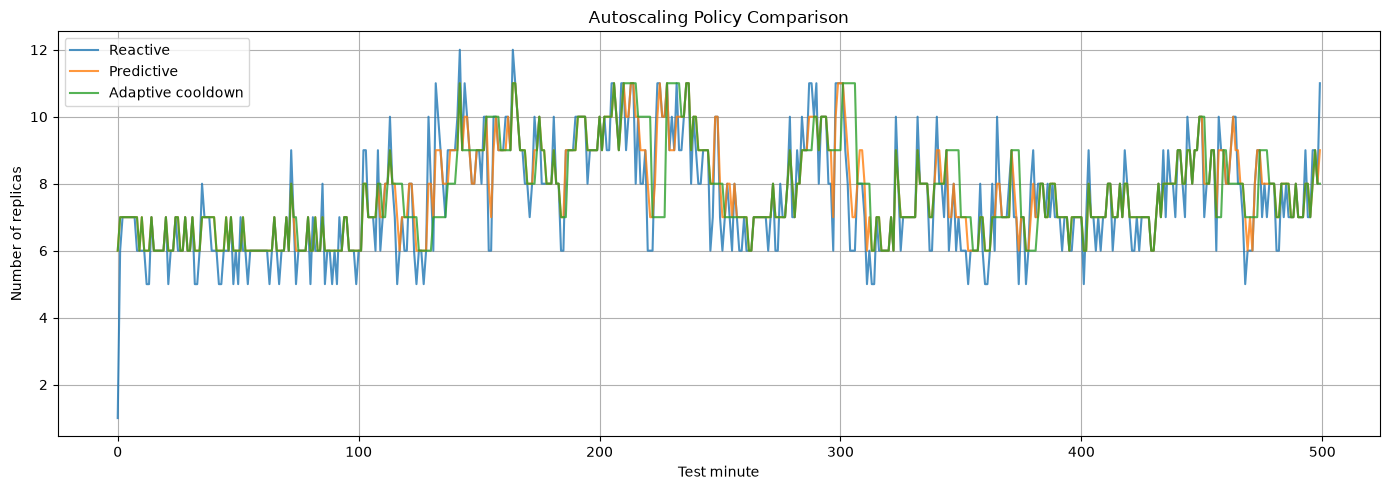

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    reactive_results["replicas"][:500],
    label="Reactive",
    alpha=0.8,
)
plt.plot(
    predictive_results["replicas"][:500],
    label="Predictive",
    alpha=0.8,
)
plt.plot(
    adaptive_results["replicas"][:500],
    label="Adaptive cooldown",
    alpha=0.8,
)

plt.xlabel("Test minute")
plt.ylabel("Number of replicas")
plt.title("Autoscaling Policy Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [17]:
comparison = pd.DataFrame([
    summarize_controller("Reactive", reactive_results),
    summarize_controller("Predictive", predictive_results),
    summarize_controller("Adaptive cooldown", adaptive_results),
])

display(comparison.round(2))

,Controller,Mean replicas,Peak replicas,Total overload requests,Minutes overloaded,Scaling changes
0,Reactive,10.93,20,90328.0,737,1392
1,Predictive,11.10,20,68937.0,589,1058
2,Adaptive cooldown,11.12,20,79518.0,623,520


In [18]:
thresholds = [75, 100, 125, 150, 200]
cooldowns = [(1, 5), (1, 8), (2, 6), (2, 10)]

tuning_results = []

for threshold in thresholds:
    for min_cd, max_cd in cooldowns:
        result = run_adaptive_scaler(
            test_raw,
            forecasts,
            base_cooldown=3,
            min_cooldown=min_cd,
            max_cooldown=max_cd,
            error_window=10,
            error_threshold=threshold,
        )

        tuning_results.append({
            "Error threshold": threshold,
            "Min cooldown": min_cd,
            "Max cooldown": max_cd,
            "Mean replicas": result["replicas"].mean(),
            "Overload requests": result["overload_requests"].sum(),
            "Overloaded minutes": result["under_capacity"].sum(),
            "Scaling changes": result["replicas"].diff().fillna(0).ne(0).sum(),
        })

tuning_df = pd.DataFrame(tuning_results)
display(
    tuning_df.sort_values(
        ["Overload requests", "Scaling changes"]
    ).round(2)
)

,Error threshold,Min cooldown,Max cooldown,Mean replicas,Overload requests,Overloaded minutes,Scaling changes
16,200,1,5,11.11,69389.0,588,1018
17,200,1,8,11.11,69991.0,586,1017
12,150,1,5,11.11,73946.0,587,876
18,200,2,6,11.12,74621.0,608,723
19,200,2,10,11.12,74621.0,608,723
13,150,1,8,11.10,77083.0,590,868
2,75,2,6,11.15,77086.0,649,361
3,75,2,10,11.15,77086.0,649,361
1,75,1,8,11.17,77614.0,644,387
6,100,2,6,11.15,77884.0,636,462


In [19]:
output_dir = Path("results/baseline")
output_dir.mkdir(parents=True, exist_ok=True)

comparison.to_csv(
    output_dir / "controller_results_corrected.csv",
    index=False,
)

In [20]:

from pathlib import Path

# Locate the project root from your current notebook directory.
project_root = Path.cwd()

# If you're in models/notebooks, move up two levels.
if project_root.name == "notebooks" and project_root.parent.name == "models":
    project_root = project_root.parent.parent

results_dir = project_root / "results" / "baseline"
results_dir.mkdir(parents=True, exist_ok=True)

assumptions = """# CNN-Transformer Autoscaling Baseline

## Workload
- Dataset: FIFA World Cup 1998 HTTP request trace
- Selected workload: seven days, aggregated into one-minute intervals
- Evaluation: chronological held-out test period

## Forecasting
- Model: CNN-Transformer
- Input sequence length: 16 minutes
- Prediction horizon: one minute
- Scaler fitted on training data only

## Autoscaling
- Replica capacity: 100 requests/minute
- Minimum replicas: 1
- Maximum replicas: 20
- Scaling delay: zero minutes (immediate)
- Initial replica count: minimum replicas
- Reactive policy: uses the previous minute's observed demand
- Predictive policy: uses the forecast for the current minute

## Limitations
- Replica capacity is a simulation assumption.
- Scaling is assumed to take effect immediately.
- Overload represents demand exceeding simulated capacity,
  not measured application latency.
- Results apply to this workload subset and evaluation period.
"""

assumptions_path = results_dir / "assumptions.md"
assumptions_path.write_text(assumptions)

print("Saved:", assumptions_path)
print("Exists:", assumptions_path.exists())


Saved: /Users/sarthak/Coding/Python-Projects/cnn-transformer-autoscaling/results/baseline/assumptions.md
Exists: True


In [21]:
from pathlib import Path

results_dir = project_root / "results" / "baseline"

for file in sorted(results_dir.iterdir()):
    print(file.name)

adaptive_per_minute.csv
assumptions.md
cnn_transformer.pth
controller_results_corrected.csv
predictive_per_minute.csv
reactive_per_minute.csv
uncertainty_aware_per_minute.csv


In [22]:


print("Actual demand:")
print("  Shape:", np.asarray(test_raw).shape)
print("  First 5:", np.asarray(test_raw)[:5])

print("\nCNN-Transformer predictions:")
print("  Shape:", np.asarray(forecasts).shape)
print("  First 5:", np.asarray(forecasts)[:5])


Actual demand:
  Shape: (2016,)
  First 5: [593. 609. 694. 670. 622.]

CNN-Transformer predictions:
  Shape: (2016,)
  First 5: [585.6165  603.0286  615.8906  665.9919  671.03284]


In [23]:

# Use the actual variable names from your notebook
actual_demand = np.asarray(test_raw, dtype=float)
predicted_demand = np.asarray(forecasts, dtype=float)

assert len(actual_demand) == len(predicted_demand)
assert len(actual_demand) > 0

print("Actual demand:", actual_demand.shape)
print("Predictions:", predicted_demand.shape)

# Run the three controllers
reactive_results = run_scaler(
    actual_demand,
    predicted_demand=None,
    cooldown_minutes=0,
)

predictive_results = run_scaler(
    actual_demand,
    predicted_demand=predicted_demand,
    cooldown_minutes=0,
)

adaptive_results = run_adaptive_scaler(
    actual_demand,
    predicted_demand,
)

print("\nAll three controllers ran successfully.")



Actual demand: (2016,)
Predictions: (2016,)

All three controllers ran successfully.


In [24]:

def summarize_controller(name, df):
    return {
        "controller": name,
        "mean_replicas": df["replicas"].mean(),
        "peak_replicas": df["replicas"].max(),
        "total_overload": df["overload_requests"].sum(),
        "minutes_overloaded": df["under_capacity"].sum(),
        "scaling_changes": (
            df["replicas"].diff().fillna(0).ne(0).sum()
        ),
    }

summary = pd.DataFrame([
    summarize_controller("Reactive", reactive_results),
    summarize_controller("Predictive", predictive_results),
    summarize_controller("Adaptive cooldown", adaptive_results),
])

display(summary)


,controller,mean_replicas,peak_replicas,total_overload,minutes_overloaded,scaling_changes
0,Reactive,10.925099,20,90328.0,737,1392
1,Predictive,11.101687,20,68937.0,589,1058
2,Adaptive cooldown,11.121528,20,79518.0,623,520


In [25]:

from pathlib import Path

project_root = Path.cwd()

# If your notebook is inside models/notebooks:
if project_root.name == "notebooks" and project_root.parent.name == "models":
    project_root = project_root.parent.parent

results_dir = project_root / "results" / "baseline"
results_dir.mkdir(parents=True, exist_ok=True)

summary.to_csv(
    results_dir / "controller_results_corrected.csv",
    index=False,
)

print("Saved to:", results_dir / "controller_results_corrected.csv")


Saved to: /Users/sarthak/Coding/Python-Projects/cnn-transformer-autoscaling/results/baseline/controller_results_corrected.csv


In [47]:

results_dir = project_root / "results" / "baseline"
results_dir.mkdir(parents=True, exist_ok=True)

reactive_results.to_csv(
    results_dir / "reactive_per_minute.csv", index=False
)
predictive_results.to_csv(
    results_dir / "predictive_per_minute.csv", index=False
)
adaptive_results.to_csv(
    results_dir / "adaptive_per_minute.csv", index=False
)

print("Saved all three per-minute simulation results.")


Saved all three per-minute simulation results.


In [48]:

def run_uncertainty_aware_scaler(
    actual_demand,
    predicted_demand,
    error_window=10,
    safety_factor=1.0,
):
    actual_demand = np.asarray(actual_demand, dtype=float)
    predicted_demand = np.asarray(predicted_demand, dtype=float)

    if len(actual_demand) != len(predicted_demand):
        raise ValueError("Actual and predicted demand lengths differ.")

    if len(actual_demand) == 0:
        raise ValueError("Demand arrays cannot be empty.")

    if error_window < 1 or safety_factor < 0:
        raise ValueError("Invalid error_window or safety_factor.")

    replicas = MIN_REPLICAS
    history = []
    past_errors = []

    for t in range(len(actual_demand)):
        forecast = max(0.0, float(predicted_demand[t]))

        # Only use errors from previous, completed forecasts.
        recent_errors = past_errors[-error_window:]

        uncertainty = (
            float(np.mean(recent_errors))
            if recent_errors else 0.0
        )

        safe_demand = forecast + safety_factor * uncertainty

        desired = required_replicas(safe_demand)
        replicas = desired

        capacity = replicas * REPLICA_CAPACITY
        actual = float(actual_demand[t])
        overload = max(0.0, actual - capacity)

        history.append({
            "minute": t,
            "actual_demand": actual,
            "forecast": forecast,
            "uncertainty": uncertainty,
            "safe_demand": safe_demand,
            "safety_factor": safety_factor,
            "replicas": replicas,
            "capacity": capacity,
            "overload_requests": overload,
            "under_capacity": actual > capacity,
        })

        # The current error is available only after this decision.
        past_errors.append(abs(actual - forecast))

    return pd.DataFrame(history)


In [49]:

uncertainty_results = run_uncertainty_aware_scaler(
    actual_demand=test_raw,
    predicted_demand=forecasts,
    error_window=10,
    safety_factor=1.0,
)

print("Uncertainty-aware controller")
print("Mean replicas:", uncertainty_results["replicas"].mean())
print("Peak replicas:", uncertainty_results["replicas"].max())
print("Total overload:", uncertainty_results["overload_requests"].sum())
print("Minutes overloaded:", uncertainty_results["under_capacity"].sum())
print(
    "Scaling changes:",
    uncertainty_results["replicas"].diff().fillna(0).ne(0).sum()
)



Uncertainty-aware controller
Mean replicas: 12.132936507936508
Peak replicas: 20
Total overload: 26948.0
Minutes overloaded: 244
Scaling changes: 953


In [50]:

uncertainty_summary = pd.DataFrame([
    summarize_controller("Reactive", reactive_results),
    summarize_controller("Predictive", predictive_results),
    summarize_controller("Adaptive cooldown", adaptive_results),
    summarize_controller("Uncertainty-aware", uncertainty_results),
])

display(uncertainty_summary)




,controller,mean_replicas,peak_replicas,total_overload,minutes_overloaded,scaling_changes
0,Reactive,10.925099,20,90328.0,737,1392
1,Predictive,11.101687,20,68937.0,589,1058
2,Adaptive cooldown,11.121528,20,79518.0,623,520
3,Uncertainty-aware,12.132937,20,26948.0,244,953


In [51]:
uncertainty_results.to_csv(
    results_dir / "uncertainty_aware_per_minute.csv",
    index=False,
)

In [26]:

uncertainty_results = run_uncertainty_aware_scaler(
    actual_demand=test_raw,
    predicted_demand=forecasts,
    error_window=10,
    safety_factor=1.0,
)

print("Uncertainty-aware controller")
print("Mean replicas:", uncertainty_results["replicas"].mean())
print("Peak replicas:", uncertainty_results["replicas"].max())
print("Total overload:", uncertainty_results["overload_requests"].sum())
print("Minutes overloaded:", uncertainty_results["under_capacity"].sum())
print(
    "Scaling changes:",
    uncertainty_results["replicas"].diff().fillna(0).ne(0).sum()
)


Uncertainty-aware controller
Mean replicas: 12.132936507936508
Peak replicas: 20
Total overload: 26948.0
Minutes overloaded: 244
Scaling changes: 953


In [27]:

uncertainty_summary = pd.DataFrame([
    summarize_controller("Reactive", reactive_results),
    summarize_controller("Predictive", predictive_results),
    summarize_controller("Adaptive cooldown", adaptive_results),
    summarize_controller("Uncertainty-aware", uncertainty_results),
])

display(uncertainty_summary)


,controller,mean_replicas,peak_replicas,total_overload,minutes_overloaded,scaling_changes
0,Reactive,10.925099,20,90328.0,737,1392
1,Predictive,11.101687,20,68937.0,589,1058
2,Adaptive cooldown,11.121528,20,79518.0,623,520
3,Uncertainty-aware,12.132937,20,26948.0,244,953


In [28]:
uncertainty_results.to_csv(
    results_dir / "uncertainty_aware_per_minute.csv",
    index=False,
)

In [29]:

safety_factors = [0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5]

tuning_results = []

for factor in safety_factors:

    result = run_uncertainty_aware_scaler(
        actual_demand=actual_demand,
        predicted_demand=predicted_demand,
        error_window=10,
        safety_factor=factor,
    )

    tuning_results.append({
        "safety_factor": factor,
        "mean_replicas": result["replicas"].mean(),
        "total_overload": result["overload_requests"].sum(),
        "minutes_overloaded": result["under_capacity"].sum(),
        "scaling_changes": (
            result["replicas"].diff().fillna(0).ne(0).sum()
        ),
    })

tuning_df = pd.DataFrame(tuning_results)

display(tuning_df)


,safety_factor,mean_replicas,total_overload,minutes_overloaded,scaling_changes
0,0.00,11.101687,68937.0,589,1058
1,0.25,11.365575,54229.0,481,1033
2,0.50,11.643353,41119.0,376,958
3,0.75,11.886409,33710.0,307,1005
4,1.00,12.132937,26948.0,244,953
5,1.25,12.393849,22092.0,196,872
6,1.50,12.617063,18958.0,170,889


In [30]:

# Calculate resource usage and improvement relative to
# ordinary predictive autoscaling.

baseline = tuning_df.loc[
    tuning_df["safety_factor"] == 0
].iloc[0]

efficiency_df = tuning_df.copy()

efficiency_df["replica_minutes"] = (
    efficiency_df["mean_replicas"] * len(actual_demand)
)

efficiency_df["overload_reduction_pct"] = (
    (baseline["total_overload"] - efficiency_df["total_overload"])
    / baseline["total_overload"] * 100
)

efficiency_df["resource_increase_pct"] = (
    (efficiency_df["mean_replicas"] - baseline["mean_replicas"])
    / baseline["mean_replicas"] * 100
)

display(efficiency_df.round(2))


,safety_factor,mean_replicas,total_overload,minutes_overloaded,scaling_changes,replica_minutes,overload_reduction_pct,resource_increase_pct
0,0.00,11.10,68937.0,589,1058,22381.0,0.00,0.00
1,0.25,11.37,54229.0,481,1033,22913.0,21.34,2.38
2,0.50,11.64,41119.0,376,958,23473.0,40.35,4.88
3,0.75,11.89,33710.0,307,1005,23963.0,51.10,7.07
4,1.00,12.13,26948.0,244,953,24460.0,60.91,9.29
5,1.25,12.39,22092.0,196,872,24986.0,67.95,11.64
6,1.50,12.62,18958.0,170,889,25436.0,72.50,13.65


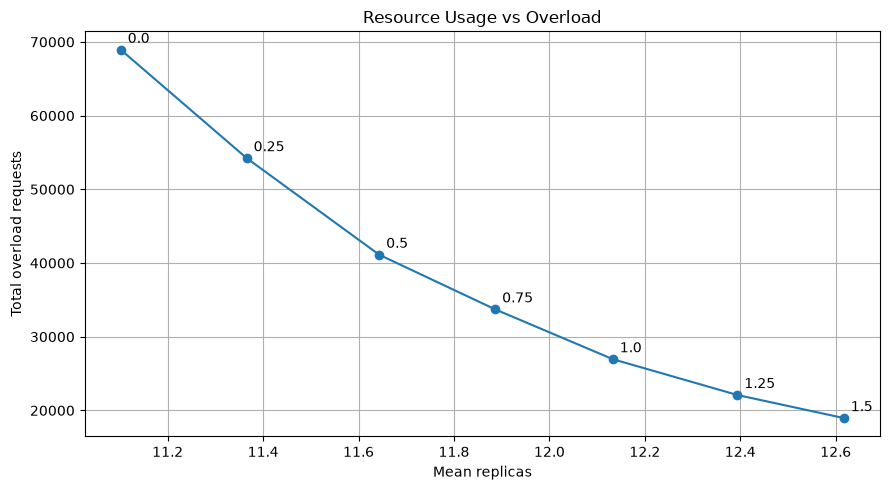

In [31]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    efficiency_df["mean_replicas"],
    efficiency_df["total_overload"],
    marker="o",
)

for _, row in efficiency_df.iterrows():
    plt.annotate(
        str(row["safety_factor"]),
        (row["mean_replicas"], row["total_overload"]),
        xytext=(5, 5),
        textcoords="offset points",
    )

plt.xlabel("Mean replicas")
plt.ylabel("Total overload requests")
plt.title("Resource Usage vs Overload")
plt.grid(True)
plt.tight_layout()
plt.show()


In [32]:
## Validation-Based Uncertainty-Aware Autoscaling

In [34]:

# Recreate the 70/10/20 split

SEQ_LEN = checkpoint["sequence_length"]

split_idx = int(len(values) * 0.7)
val_idx = split_idx + int(len(values) * 0.1)

train_raw = values[:split_idx]
val_raw = values[split_idx:val_idx]

# Fit scaler only on training data
scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(
    train_raw.reshape(-1, 1)
).astype(np.float32).flatten()

val_scaled = scaler.transform(
    val_raw.reshape(-1, 1)
).astype(np.float32).flatten()

# Include the final training observations as validation context
val_context = np.concatenate([
    train_scaled[-SEQ_LEN:],
    val_scaled
])

# Generate validation sequences
X_val = []
y_val = []

for i in range(len(val_context) - SEQ_LEN):
    X_val.append(val_context[i:i + SEQ_LEN])
    y_val.append(val_context[i + SEQ_LEN])

X_val = np.asarray(X_val, dtype=np.float32)[..., None]
y_val = np.asarray(y_val, dtype=np.float32)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

X_val: (1008, 16, 1)
y_val: (1008,)


In [35]:
model.eval()

X_val_tensor = torch.from_numpy(X_val).to(device)

with torch.no_grad():
    val_predictions_scaled = (
        model(X_val_tensor).cpu().numpy().flatten()
    )

val_predictions = scaler.inverse_transform(
    val_predictions_scaled.reshape(-1, 1)
).flatten()

val_actual = scaler.inverse_transform(
    y_val.reshape(-1, 1)
).flatten()

val_predictions = np.maximum(val_predictions, 0)

print("Actual:", len(val_actual))
print("Predictions:", len(val_predictions))

assert len(val_actual) == 1008
assert len(val_predictions) == 1008

Actual: 1008
Predictions: 1008


In [36]:

def run_uncertainty_controller(
    actual_demand,
    predicted_demand,
    safety_factor,
    error_window=10
):
    replicas = MIN_REPLICAS
    last_scale_time = -10**9

    history = []
    recent_errors = []

    for t, actual in enumerate(actual_demand):

        forecast = max(0, float(predicted_demand[t]))

        # Only use errors from previous minutes.
        if t > 0:
            previous_error = abs(
                float(actual_demand[t - 1])
                - float(predicted_demand[t - 1])
            )
            recent_errors.append(previous_error)

        recent_errors = recent_errors[-error_window:]

        # Estimate uncertainty from recent forecast errors.
        uncertainty = (
            float(np.mean(recent_errors))
            if recent_errors else 0.0
        )

        # Increase forecast using the safety factor.
        adjusted_demand = (
            forecast + safety_factor * uncertainty
        )

        desired = required_replicas(adjusted_demand)

        # Scale immediately when required.
        if desired != replicas:
            replicas = desired
            last_scale_time = t

        capacity = replicas * REPLICA_CAPACITY
        overload = max(0, float(actual) - capacity)

        history.append({
            "minute": t,
            "actual_demand": float(actual),
            "forecast": forecast,
            "uncertainty": uncertainty,
            "adjusted_demand": adjusted_demand,
            "replicas": replicas,
            "capacity": capacity,
            "overload_requests": overload,
            "under_capacity": actual > capacity
        })

    return pd.DataFrame(history)


In [39]:
safety_factors = [
    0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5
]

results = []

for alpha in safety_factors:

    simulation = run_uncertainty_controller(
        actual_demand=val_actual,
        predicted_demand=val_predictions,
        safety_factor=alpha
    )

    results.append({
        "safety_factor": alpha,
        "mean_replicas": simulation["replicas"].mean(),
        "total_overload": simulation["overload_requests"].sum(),
        "minutes_overloaded": simulation["under_capacity"].sum(),
        "scaling_changes": (
            simulation["replicas"].diff().fillna(0) != 0
        ).sum(),
        "replica_minutes": simulation["replicas"].sum()
    })

validation_sweep = pd.DataFrame(results)

display(validation_sweep.round(2))

,safety_factor,mean_replicas,total_overload,minutes_overloaded,scaling_changes,replica_minutes
0,0.00,6.14,10141.0,193,333,6194
1,0.25,6.31,7599.0,148,347,6363
2,0.50,6.47,5933.0,123,370,6520
3,0.75,6.64,4032.0,85,353,6692
4,1.00,6.81,2615.0,54,327,6867
5,1.25,6.99,1889.0,36,325,7044
6,1.50,7.16,1333.0,25,313,7220


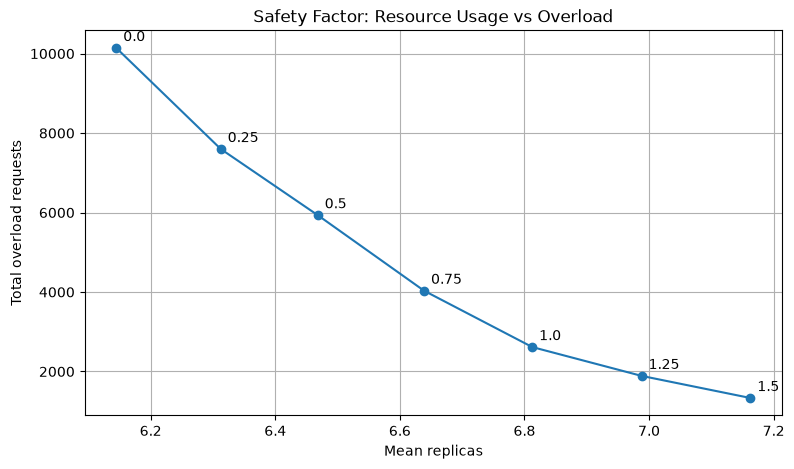

In [40]:
plt.figure(figsize=(9, 5))

plt.plot(
    validation_sweep["mean_replicas"],
    validation_sweep["total_overload"],
    marker="o"
)

for _, row in validation_sweep.iterrows():
    plt.annotate(
        str(row["safety_factor"]),
        (row["mean_replicas"], row["total_overload"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Mean replicas")
plt.ylabel("Total overload requests")
plt.title("Safety Factor: Resource Usage vs Overload")
plt.grid(True)
plt.show()

In [41]:

# Compare controllers on the SAME validation workload

reactive_val = run_scaler(
    val_actual,
    predicted_demand=None,
    cooldown_minutes=0
)

predictive_val = run_scaler(
    val_actual,
    predicted_demand=val_predictions,
    cooldown_minutes=0
)

uncertainty_val = run_uncertainty_controller(
    actual_demand=val_actual,
    predicted_demand=val_predictions,
    safety_factor=1.0
)

def summarize_controller(name, result):
    return {
        "controller": name,
        "mean_replicas": result["replicas"].mean(),
        "total_overload": result["overload_requests"].sum(),
        "minutes_overloaded": result["under_capacity"].sum(),
        "scaling_changes": (
            result["replicas"].diff().fillna(0) != 0
        ).sum(),
        "replica_minutes": result["replicas"].sum()
    }

comparison = pd.DataFrame([
    summarize_controller("Reactive", reactive_val),
    summarize_controller("Predictive", predictive_val),
    summarize_controller("Uncertainty-aware (1.0)", uncertainty_val)
])

display(comparison.round(2))


,controller,mean_replicas,total_overload,minutes_overloaded,scaling_changes,replica_minutes
0,Reactive,5.91,20361.0,319,627,5958
1,Predictive,6.14,10141.0,193,333,6194
2,Uncertainty-aware (1.0),6.81,2615.0,54,327,6867


In [42]:
results_dir = PROJECT_ROOT / "results" / "validation"
results_dir.mkdir(parents=True, exist_ok=True)

comparison.to_csv(
    results_dir / "controller_comparison.csv",
    index=False
)

validation_sweep.to_csv(
    results_dir / "safety_factor_sweep.csv",
    index=False
)

print("Validation results saved.")

Validation results saved.


In [43]:
SELECTED_SAFETY_FACTOR = 1.0

print("Frozen safety factor:", SELECTED_SAFETY_FACTOR)

Frozen safety factor: 1.0


In [44]:

# FINAL TEST DATA PREPARATION

SEQ_LEN = 16
SELECTED_SAFETY_FACTOR = 1.0

split_idx = int(len(values) * 0.7)
val_idx = split_idx + int(len(values) * 0.1)

train_raw = values[:split_idx]
val_raw = values[split_idx:val_idx]
test_raw = values[val_idx:]

# Fit scaler only on training data
final_scaler = MinMaxScaler()

train_scaled = final_scaler.fit_transform(
    train_raw.reshape(-1, 1)
).astype(np.float32).flatten()

val_scaled = final_scaler.transform(
    val_raw.reshape(-1, 1)
).astype(np.float32).flatten()

test_scaled = final_scaler.transform(
    test_raw.reshape(-1, 1)
).astype(np.float32).flatten()

# Use the preceding 16 observations as context
test_context = np.concatenate([
    train_scaled,
    val_scaled
])[-SEQ_LEN:]

test_context = np.concatenate([
    test_context,
    test_scaled
])

X_test, y_test = [], []

for i in range(len(test_context) - SEQ_LEN):
    X_test.append(test_context[i:i + SEQ_LEN])
    y_test.append(test_context[i + SEQ_LEN])

X_test = np.asarray(
    X_test, dtype=np.float32
)[..., None]

y_test = np.asarray(y_test, dtype=np.float32)

test_actual = final_scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

print("Training observations:", len(train_raw))
print("Validation observations:", len(val_raw))
print("Test observations:", len(test_raw))
print("Test input shape:", X_test.shape)
print("Test actual shape:", test_actual.shape)

assert len(test_actual) == len(test_raw)


Training observations: 7056
Validation observations: 1008
Test observations: 2016
Test input shape: (2016, 16, 1)
Test actual shape: (2016,)


In [45]:

# LOAD THE 70/10/20 CHECKPOINT

model_path = (
    PROJECT_ROOT / "models" / "cnn_transformer_70_10_20.pth"
)

checkpoint = torch.load(
    model_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

X_test_tensor = torch.from_numpy(X_test).to(device)

with torch.no_grad():
    test_predictions_scaled = (
        model(X_test_tensor).cpu().numpy().flatten()
    )

test_predictions = final_scaler.inverse_transform(
    test_predictions_scaled.reshape(-1, 1)
).flatten()

test_predictions = np.maximum(test_predictions, 0)

print("Test predictions:", len(test_predictions))
print("Test actual:", len(test_actual))

assert len(test_predictions) == len(test_actual)


Test predictions: 2016
Test actual: 2016


In [46]:

from sklearn.metrics import mean_squared_error, mean_absolute_error

test_rmse = np.sqrt(
    mean_squared_error(test_actual, test_predictions)
)

test_mae = mean_absolute_error(
    test_actual, test_predictions
)

nonzero = test_actual != 0

test_mape = np.mean(
    np.abs(
        (test_actual[nonzero] - test_predictions[nonzero])
        / test_actual[nonzero]
    )
) * 100

print("FINAL TEST FORECAST METRICS")
print("---------------------------")
print("RMSE:", round(test_rmse, 2))
print("MAE:", round(test_mae, 2))
print("MAPE:", round(test_mape, 2), "%")


FINAL TEST FORECAST METRICS
---------------------------
RMSE: 156.68
MAE: 112.96
MAPE: 11.58 %


In [48]:

# Calculate absolute forecast errors on the validation set

val_abs_errors = np.abs(
    val_actual - val_predictions
)

print("Validation errors calculated:", len(val_abs_errors))
print("Mean absolute validation error:", round(val_abs_errors.mean(), 2))
print("Median absolute validation error:", round(np.median(val_abs_errors), 2))


Validation errors calculated: 1008
Mean absolute validation error: 68.18
Median absolute validation error: 57.38


In [49]:

# REACTIVE CONTROLLER WITH NO FUTURE INFORMATION

def run_reactive_final(actual_demand, previous_observation):
    replicas = MIN_REPLICAS
    history = []

    previous_demand = float(previous_observation)

    for t, actual in enumerate(actual_demand):

        desired = required_replicas(previous_demand)
        replicas = desired

        capacity = replicas * REPLICA_CAPACITY
        overload = max(0, float(actual) - capacity)

        history.append({
            "minute": t,
            "actual_demand": float(actual),
            "replicas": replicas,
            "capacity": capacity,
            "overload_requests": overload,
            "under_capacity": actual > capacity
        })

        # This observation becomes available for the next decision.
        previous_demand = float(actual)

    return pd.DataFrame(history)


# UNCERTAINTY-AWARE CONTROLLER

def run_uncertainty_final(
    actual_demand,
    predicted_demand,
    initial_errors,
    safety_factor=1.0,
    error_window=10
):
    replicas = MIN_REPLICAS
    history = []

    # Initialize uncertainty using validation errors only.
    recent_errors = list(initial_errors[-error_window:])

    for t, (actual, forecast) in enumerate(
        zip(actual_demand, predicted_demand)
    ):

        uncertainty = (
            float(np.mean(recent_errors))
            if recent_errors else 0.0
        )

        adjusted_demand = (
            max(0, float(forecast))
            + safety_factor * uncertainty
        )

        desired = required_replicas(adjusted_demand)
        replicas = desired

        capacity = replicas * REPLICA_CAPACITY
        overload = max(0, float(actual) - capacity)

        history.append({
            "minute": t,
            "actual_demand": float(actual),
            "forecast": float(forecast),
            "uncertainty": uncertainty,
            "adjusted_demand": adjusted_demand,
            "replicas": replicas,
            "capacity": capacity,
            "overload_requests": overload,
            "under_capacity": actual > capacity
        })

        # Update uncertainty only after observing this minute's demand.
        current_error = abs(
            float(actual) - float(forecast)
        )

        recent_errors.append(current_error)
        recent_errors = recent_errors[-error_window:]

    return pd.DataFrame(history)


# Run all controllers

reactive_test = run_reactive_final(
    test_actual,
    previous_observation=val_actual[-1]
)

predictive_test = run_scaler(
    actual_demand=test_actual,
    predicted_demand=test_predictions,
    cooldown_minutes=0
)

uncertainty_test = run_uncertainty_final(
    actual_demand=test_actual,
    predicted_demand=test_predictions,
    initial_errors=val_abs_errors,
    safety_factor=SELECTED_SAFETY_FACTOR
)

print("All three final test simulations completed.")


All three final test simulations completed.


In [50]:

def summarize_final(name, result):

    return {
        "controller": name,
        "mean_replicas": result["replicas"].mean(),
        "peak_replicas": result["replicas"].max(),
        "total_overload": result["overload_requests"].sum(),
        "minutes_overloaded": result["under_capacity"].sum(),
        "scaling_changes": (
            result["replicas"].diff().fillna(0) != 0
        ).sum(),
        "replica_minutes": result["replicas"].sum()
    }


final_comparison = pd.DataFrame([
    summarize_final("Reactive", reactive_test),
    summarize_final("Predictive", predictive_test),
    summarize_final(
        "Uncertainty-aware",
        uncertainty_test
    )
])

display(final_comparison.round(2))


,controller,mean_replicas,peak_replicas,total_overload,minutes_overloaded,scaling_changes,replica_minutes
0,Reactive,10.93,20,89835.0,736,1391,22030
1,Predictive,10.70,20,97941.0,806,958,21581
2,Uncertainty-aware,11.78,20,37621.0,342,954,23756


In [51]:
 
final_dir = PROJECT_ROOT / "results" / "final_test"
final_dir.mkdir(parents=True, exist_ok=True)

final_comparison.to_csv(
    final_dir / "final_controller_comparison.csv",
    index=False
)

# Save individual minute-by-minute results
reactive_test.to_csv(
    final_dir / "reactive_test_results.csv",
    index=False
)

predictive_test.to_csv(
    final_dir / "predictive_test_results.csv",
    index=False
)

uncertainty_test.to_csv(
    final_dir / "uncertainty_aware_test_results.csv",
    index=False
)

# Save forecasting predictions
pd.DataFrame({
    "actual": test_actual,
    "predicted": test_predictions
}).to_csv(
    final_dir / "test_forecasts.csv",
    index=False
)

print("Final results saved to:", final_dir)


Final results saved to: /Users/sarthak/Coding/Python-Projects/cnn-transformer-autoscaling/results/final_test


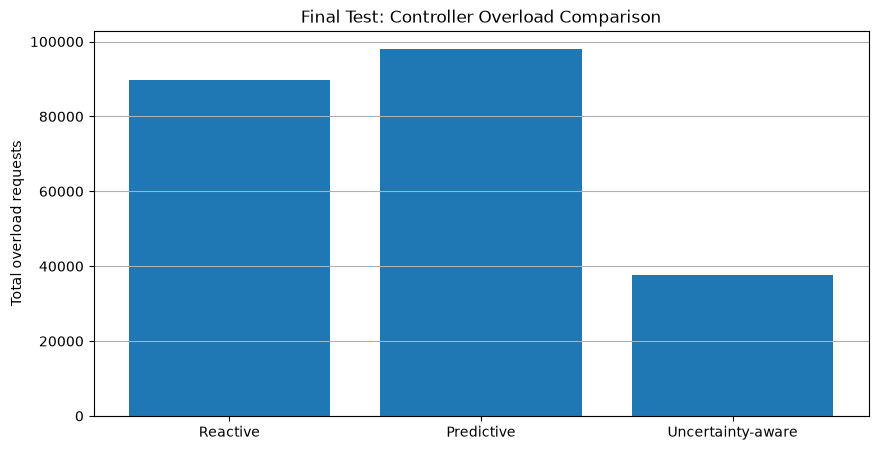

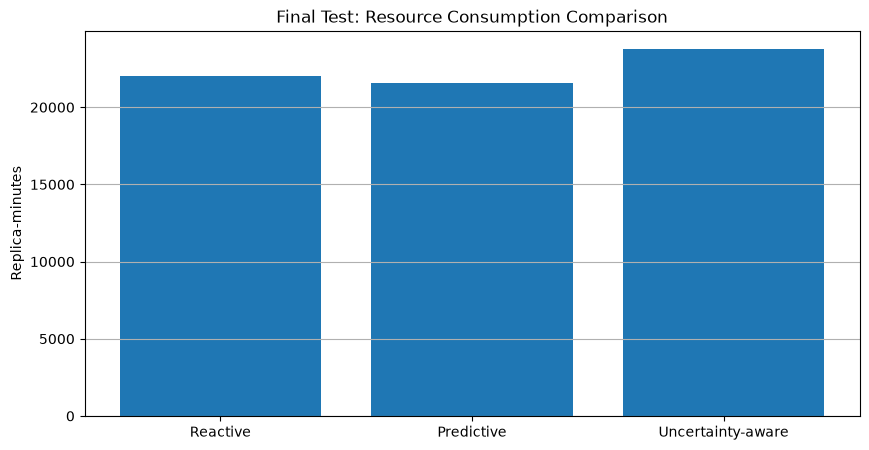

In [52]:

plt.figure(figsize=(10, 5))

plt.bar(
    final_comparison["controller"],
    final_comparison["total_overload"]
)

plt.ylabel("Total overload requests")
plt.title("Final Test: Controller Overload Comparison")
plt.grid(axis="y")
plt.show()

plt.figure(figsize=(10, 5))

plt.bar(
    final_comparison["controller"],
    final_comparison["replica_minutes"]
)

plt.ylabel("Replica-minutes")
plt.title("Final Test: Resource Consumption Comparison")
plt.grid(axis="y")
plt.show()
